# AFLW2000-3D Dataset - EDA

本notebook用于探索和分析AFLW2000-3D头部姿态数据集。

## 数据集信息
- **来源**: Annotated Facial Landmarks in the Wild (AFLW)
- **样本数量**: 2000张图像
- **标注内容**: 3D人脸关键点 (68点) + 头部姿态 (Pitch/Yaw/Roll)
- **文件格式**: `.jpg` (图像) + `.mat` (MATLAB标注文件)
- **特点**: 大角度姿态、真实场景、多样化光照


In [48]:
import os
import glob
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict, Counter
import cv2
from scipy.io import loadmat
from scipy.spatial.transform import Rotation as R

mpl.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Songti SC', 'Arial Unicode MS']
mpl.rcParams['axes.unicode_minus'] = False  # 负号正常显示

# 设置数据集路径 - 请根据实际情况修改
DATASET_ROOT = os.path.expanduser("~/temp/public_dataset/AFLW2000")

# 检查目录是否存在
print("=" * 60)
print("AFLW2000-3D Dataset Directory")
print("=" * 60)
print(f"路径: {DATASET_ROOT}")
print(f"存在: {'✅ 是' if os.path.exists(DATASET_ROOT) else '❌ 否'}")

if os.path.exists(DATASET_ROOT):
    all_files = os.listdir(DATASET_ROOT)
    print(f"总文件数: {len(all_files)}")


AFLW2000-3D Dataset Directory
路径: /Users/eddiesyn/temp/public_dataset/AFLW2000
存在: ✅ 是
总文件数: 4001


## 1. 数据集文件结构分析


In [49]:
# 统计文件类型分布
print("=" * 60)
print("文件类型分布")
print("=" * 60)

extensions = defaultdict(list)
for f in os.listdir(DATASET_ROOT):
    ext = os.path.splitext(f)[1].lower()
    extensions[ext].append(f)

for ext, files in sorted(extensions.items(), key=lambda x: -len(x[1])):
    print(f"  {ext if ext else '(无扩展名)'}: {len(files)} 个文件")

# 获取图像和mat文件列表
jpg_files = sorted(extensions.get('.jpg', []))
mat_files = sorted(extensions.get('.mat', []))

print(f"\n图像文件 (.jpg): {len(jpg_files)}")
print(f"标注文件 (.mat): {len(mat_files)}")

# 检查图像和mat文件是否一一对应
jpg_basenames = set(os.path.splitext(f)[0] for f in jpg_files)
mat_basenames = set(os.path.splitext(f)[0] for f in mat_files)

matched = jpg_basenames & mat_basenames
jpg_only = jpg_basenames - mat_basenames
mat_only = mat_basenames - jpg_basenames

print(f"\n文件匹配情况:")
print(f"  ✅ 完整配对: {len(matched)}")
print(f"  ⚠️ 仅有图像: {len(jpg_only)}")
print(f"  ⚠️ 仅有标注: {len(mat_only)}")


文件类型分布
  .mat: 2000 个文件
  .jpg: 2000 个文件
  (无扩展名): 1 个文件

图像文件 (.jpg): 2000
标注文件 (.mat): 2000

文件匹配情况:
  ✅ 完整配对: 2000
  ⚠️ 仅有图像: 0
  ⚠️ 仅有标注: 0


In [50]:
# 显示文件名示例
print("文件名示例 (前10个):")
for f in jpg_files[:10]:
    print(f"  {f}")


文件名示例 (前10个):
  image00002.jpg
  image00004.jpg
  image00006.jpg
  image00008.jpg
  image00010.jpg
  image00013.jpg
  image00014.jpg
  image00019.jpg
  image00020.jpg
  image00021.jpg


## 2. 解析 MAT 标注文件

AFLW2000 的 `.mat` 文件通常包含以下字段:
- `pt3d_68`: 68个3D人脸关键点坐标 (3 x 68)
- `Pose_Para`: 姿态参数 [pitch, yaw, roll, tx, ty, tz, scale]
- `roi`: 人脸边界框


In [51]:
def map_to_pi(angle_rad):
    """
    将弧度角度标准化到 [-π, π] 范围
    参考 Kaggle notebook 的实现
    """
    return (angle_rad + np.pi) % (2 * np.pi) - np.pi


def parse_aflw_mat(mat_path):
    """
    解析AFLW2000的MAT标注文件
    
    AFLW2000 (来自3DDFA) 的 Pose_Para 格式:
    - [pitch, yaw, roll, tx, ty, tz, scale]
    - 前3个是欧拉角 (弧度)
    - 参考: https://www.kaggle.com/code/raedalkhatib/head-pose-estimation
    
    返回:
        - landmarks_3d: 68个3D关键点 (68, 3)
        - pose: [pitch, yaw, roll] 欧拉角 (degrees)，已标准化到 [-180, 180]
        - roi: 人脸边界框 [x1, y1, x2, y2]
    """
    try:
        mat_data = loadmat(mat_path)
        
        # 提取3D关键点 (通常是 3x68 的矩阵)
        landmarks_3d = None
        for key in ['pt3d_68', 'pts_3d', 'pt3d']:
            if key in mat_data:
                landmarks_3d = mat_data[key]
                if landmarks_3d.shape[0] == 3:
                    landmarks_3d = landmarks_3d.T  # 转置为 (68, 3)
                break
        
        # 提取姿态参数
        pose = None
        for key in ['Pose_Para', 'pose', 'Pose']:
            if key in mat_data:
                pose_para = mat_data[key].flatten()
                if len(pose_para) >= 3:
                    # 提取原始弧度值
                    pitch_rad = float(pose_para[0])
                    yaw_rad = float(pose_para[1])
                    roll_rad = float(pose_para[2])
                    
                    # 先在弧度域标准化到 [-π, π] (参考 Kaggle 实现)
                    pitch_rad = map_to_pi(pitch_rad)
                    yaw_rad = map_to_pi(yaw_rad)
                    roll_rad = map_to_pi(roll_rad)
                    
                    # 然后转换为度数
                    pitch = np.degrees(pitch_rad)
                    yaw = np.degrees(yaw_rad)
                    roll = np.degrees(roll_rad)
                    
                    pose = np.array([pitch, yaw, roll])
                break
        
        # 提取ROI
        roi = None
        for key in ['roi', 'bbox', 'Roi']:
            if key in mat_data:
                roi = mat_data[key].flatten()
                break
        
        return landmarks_3d, pose, roi, mat_data.keys()
        
    except Exception as e:
        return None, None, None, str(e)


# 测试解析函数
print("=" * 60)
print("测试MAT文件解析")
print("=" * 60)

# 解析前几个mat文件作为示例
for mat_file in mat_files[:3]:
    mat_path = os.path.join(DATASET_ROOT, mat_file)
    print(f"\n文件: {mat_file}")
    print("-" * 50)
    
    landmarks, pose, roi, keys = parse_aflw_mat(mat_path)
    
    print(f"MAT文件键: {[k for k in keys if not k.startswith('__')]}")
    
    if landmarks is not None:
        print(f"\n✅ 3D关键点: shape = {landmarks.shape}")
        print(f"   X范围: [{landmarks[:, 0].min():.2f}, {landmarks[:, 0].max():.2f}]")
        print(f"   Y范围: [{landmarks[:, 1].min():.2f}, {landmarks[:, 1].max():.2f}]")
        print(f"   Z范围: [{landmarks[:, 2].min():.2f}, {landmarks[:, 2].max():.2f}]")
    
    if pose is not None:
        print(f"\n✅ 姿态角度:")
        print(f"   Pitch (俯仰): {pose[0]:.2f}°")
        print(f"   Yaw (偏航):   {pose[1]:.2f}°")
        print(f"   Roll (滚转):  {pose[2]:.2f}°")
    
    if roi is not None:
        print(f"\n✅ ROI (人脸边界框): {roi}")


测试MAT文件解析

文件: image00002.mat
--------------------------------------------------
MAT文件键: ['pt2d', 'Illum_Para', 'Color_Para', 'Tex_Para', 'Shape_Para', 'Exp_Para', 'Pose_Para', 'roi', 'pt3d_68']

✅ 3D关键点: shape = (68, 3)
   X范围: [121.87, 345.24]
   Y范围: [167.16, 375.73]
   Z范围: [-92.75, 85.37]

✅ 姿态角度:
   Pitch (俯仰): -22.87°
   Yaw (偏航):   1.04°
   Roll (滚转):  4.91°

✅ ROI (人脸边界框): [ 13 -26 437 398]

文件: image00004.mat
--------------------------------------------------
MAT文件键: ['pt2d', 'Illum_Para', 'Color_Para', 'Tex_Para', 'Shape_Para', 'Exp_Para', 'Pose_Para', 'roi', 'pt3d_68']

✅ 3D关键点: shape = (68, 3)
   X范围: [186.15, 341.29]
   Y范围: [196.59, 350.93]
   Z范围: [-120.26, 48.51]

✅ 姿态角度:
   Pitch (俯仰): 26.93°
   Yaw (偏航):   68.16°
   Roll (滚转):  17.24°

✅ ROI (人脸边界框): [336 -15 450  99]

文件: image00006.mat
--------------------------------------------------
MAT文件键: ['pt2d', 'Illum_Para', 'Color_Para', 'Tex_Para', 'Shape_Para', 'Exp_Para', 'Pose_Para', 'roi', 'pt3d_68']

✅ 3D关键点: shape =

In [52]:
# 详细查看一个MAT文件的所有内容
print("=" * 60)
print("MAT文件详细内容分析")
print("=" * 60)

if mat_files:
    sample_mat = os.path.join(DATASET_ROOT, mat_files[0])
    mat_data = loadmat(sample_mat)
    
    print(f"文件: {mat_files[0]}\n")
    
    for key, value in mat_data.items():
        if not key.startswith('__'):
            if isinstance(value, np.ndarray):
                print(f"{key}:")
                print(f"  类型: numpy.ndarray")
                print(f"  形状: {value.shape}")
                print(f"  数据类型: {value.dtype}")
                if value.size <= 20:
                    print(f"  值: {value.flatten()}")
                else:
                    print(f"  前10个值: {value.flatten()[:10]}...")
                print()
            else:
                print(f"{key}: {type(value).__name__} = {value}\n")


MAT文件详细内容分析
文件: image00002.mat

pt2d:
  类型: numpy.ndarray
  形状: (2, 21)
  数据类型: float64
  前10个值: [145.50226907 172.52941176 204.29411765 269.94117647 296.41176471
 319.70588235 158.76470588 182.05882353 203.23529412 257.23529412]...

Illum_Para:
  类型: numpy.ndarray
  形状: (1, 10)
  数据类型: float64
  值: [ 1.18886197  1.09708118  1.01795137  0.1650033   0.28545761  0.43338135
  1.32711709 -0.73413867  0.         20.        ]

Color_Para:
  类型: numpy.ndarray
  形状: (1, 7)
  数据类型: float32
  值: [ 1.348765    1.0940965   0.9754355  -0.6081605  -0.2021448  -0.12822138
  1.        ]

Tex_Para:
  类型: numpy.ndarray
  形状: (199, 1)
  数据类型: float64
  前10个值: [ 1934.7722168   9404.73925781 -1588.68383789 -2615.1809082
  -174.8734436   1865.05151367  -918.3458252     38.7341156
   441.18740845  -826.96636963]...

Shape_Para:
  类型: numpy.ndarray
  形状: (199, 1)
  数据类型: float64
  前10个值: [-4.69857531e+05 -3.00033320e+04  3.69438938e+05 -1.11457275e+02
 -2.39598516e+04 -3.51526406e+04 -1.02700094e+05 -2.108915

## 3. 收集所有姿态数据


In [53]:
def collect_all_poses(dataset_root, mat_files):
    """
    遍历所有MAT标注文件，收集姿态角数据
    """
    all_pitches = []
    all_yaws = []
    all_rolls = []
    failed_files = []
    all_landmarks = []
    
    print(f"正在处理 {len(mat_files)} 个MAT文件...")
    
    for mat_file in mat_files:
        mat_path = os.path.join(dataset_root, mat_file)
        landmarks, pose, roi, _ = parse_aflw_mat(mat_path)
        
        if pose is not None and len(pose) >= 3:
            all_pitches.append(pose[0])
            all_yaws.append(pose[1])
            all_rolls.append(pose[2])
            
            if landmarks is not None:
                all_landmarks.append(landmarks)
        else:
            failed_files.append(mat_file)
    
    return (np.array(all_pitches), np.array(all_yaws), np.array(all_rolls), 
            all_landmarks, failed_files)


# 收集数据
pitches, yaws, rolls, landmarks_list, failed = collect_all_poses(DATASET_ROOT, mat_files)

print(f"\n成功解析: {len(pitches)} 个样本")
print(f"解析失败: {len(failed)} 个文件")

if len(failed) > 0:
    print(f"\n失败文件示例: {failed[:5]}")


正在处理 2000 个MAT文件...

成功解析: 2000 个样本
解析失败: 0 个文件


In [54]:
# 欧拉角统计摘要
if len(pitches) > 0:
    print("=" * 60)
    print("欧拉角统计摘要")
    print("=" * 60)
    print("注: 角度已在弧度域标准化到 [-π, π]，再转换为度数")
    
    print(f"\n【全部样本统计】(共 {len(pitches)} 个)")
    print(f"\nPitch (俯仰角 - 点头):")
    print(f"  范围: [{pitches.min():.1f}°, {pitches.max():.1f}°]")
    print(f"  均值: {pitches.mean():.1f}°  标准差: {pitches.std():.1f}°")
    
    print(f"\nYaw (偏航角 - 摇头):")
    print(f"  范围: [{yaws.min():.1f}°, {yaws.max():.1f}°]")
    print(f"  均值: {yaws.mean():.1f}°  标准差: {yaws.std():.1f}°")
    
    print(f"\nRoll (滚转角 - 歪头):")
    print(f"  范围: [{rolls.min():.1f}°, {rolls.max():.1f}°]")
    print(f"  均值: {rolls.mean():.1f}°  标准差: {rolls.std():.1f}°")
    
    # 过滤到合理范围
    print("\n" + "-" * 60)
    print("【按角度范围过滤】")
    print("-" * 60)
    
    # ±90° 范围
    mask_90 = (np.abs(pitches) <= 90) & (np.abs(yaws) <= 90) & (np.abs(rolls) <= 90)
    n_90 = mask_90.sum()
    print(f"\n|angle| ≤ 90° 的样本: {n_90} ({100*n_90/len(pitches):.1f}%)")
    if n_90 > 0:
        print(f"  Pitch: [{pitches[mask_90].min():.1f}°, {pitches[mask_90].max():.1f}°]")
        print(f"  Yaw:   [{yaws[mask_90].min():.1f}°, {yaws[mask_90].max():.1f}°]")
        print(f"  Roll:  [{rolls[mask_90].min():.1f}°, {rolls[mask_90].max():.1f}°]")
    
    # ±99° 范围 (常用评估阈值)
    mask_99 = (np.abs(pitches) <= 99) & (np.abs(yaws) <= 99) & (np.abs(rolls) <= 99)
    n_99 = mask_99.sum()
    print(f"\n|angle| ≤ 99° 的样本 (常用评估): {n_99} ({100*n_99/len(pitches):.1f}%)")
    
    # 极端样本
    extreme_mask = (np.abs(pitches) > 90) | (np.abs(yaws) > 90) | (np.abs(rolls) > 90)
    n_extreme = extreme_mask.sum()
    print(f"\n⚠️ 极端样本 (|angle| > 90°): {n_extreme} ({100*n_extreme/len(pitches):.1f}%)")
    print("   这些样本可能有标注问题或是极端视角，训练时建议过滤")
    
    # 各角度区间分布 (只统计 ±90° 范围)
    print("\n" + "-" * 60)
    print("姿态角度区间分布 (仅统计 ±90° 范围内):")
    print("-" * 60)
    
    bins = [(-90, -60), (-60, -30), (-30, 0), (0, 30), (30, 60), (60, 90)]
    
    for angle_name, angles in [('Pitch', pitches), ('Yaw', yaws), ('Roll', rolls)]:
        print(f"\n{angle_name}:")
        for low, high in bins:
            count = np.sum((angles >= low) & (angles < high))
            pct = 100 * count / len(angles)
            bar = '█' * int(pct / 2)
            print(f"  [{low:+4d}°, {high:+3d}°): {count:4d} ({pct:5.1f}%) {bar}")


欧拉角统计摘要
注: 角度已在弧度域标准化到 [-π, π]，再转换为度数

【全部样本统计】(共 2000 个)

Pitch (俯仰角 - 点头):
  范围: [-164.1°, 173.7°]
  均值: -5.4°  标准差: 22.3°

Yaw (偏航角 - 摇头):
  范围: [-172.2°, 118.9°]
  均值: 0.8°  标准差: 36.6°

Roll (滚转角 - 歪头):
  范围: [-161.1°, 159.2°]
  均值: -1.1°  标准差: 24.2°

------------------------------------------------------------
【按角度范围过滤】
------------------------------------------------------------

|angle| ≤ 90° 的样本: 1964 (98.2%)
  Pitch: [-83.0°, 88.3°]
  Yaw:   [-83.7°, 86.6°]
  Roll:  [-87.1°, 83.7°]

|angle| ≤ 99° 的样本 (常用评估): 1969 (98.5%)

⚠️ 极端样本 (|angle| > 90°): 36 (1.8%)
   这些样本可能有标注问题或是极端视角，训练时建议过滤

------------------------------------------------------------
姿态角度区间分布 (仅统计 ±90° 范围内):
------------------------------------------------------------

Pitch:
  [ -90°, -60°):   23 (  1.1%) 
  [ -60°, -30°):   71 (  3.5%) █
  [ -30°,  +0°): 1283 ( 64.2%) ████████████████████████████████
  [  +0°, +30°):  531 ( 26.6%) █████████████
  [ +30°, +60°):   58 (  2.9%) █
  [ +60°, +90°):   11 (  0.6%) 

Yaw

## 4. 欧拉角分布可视化


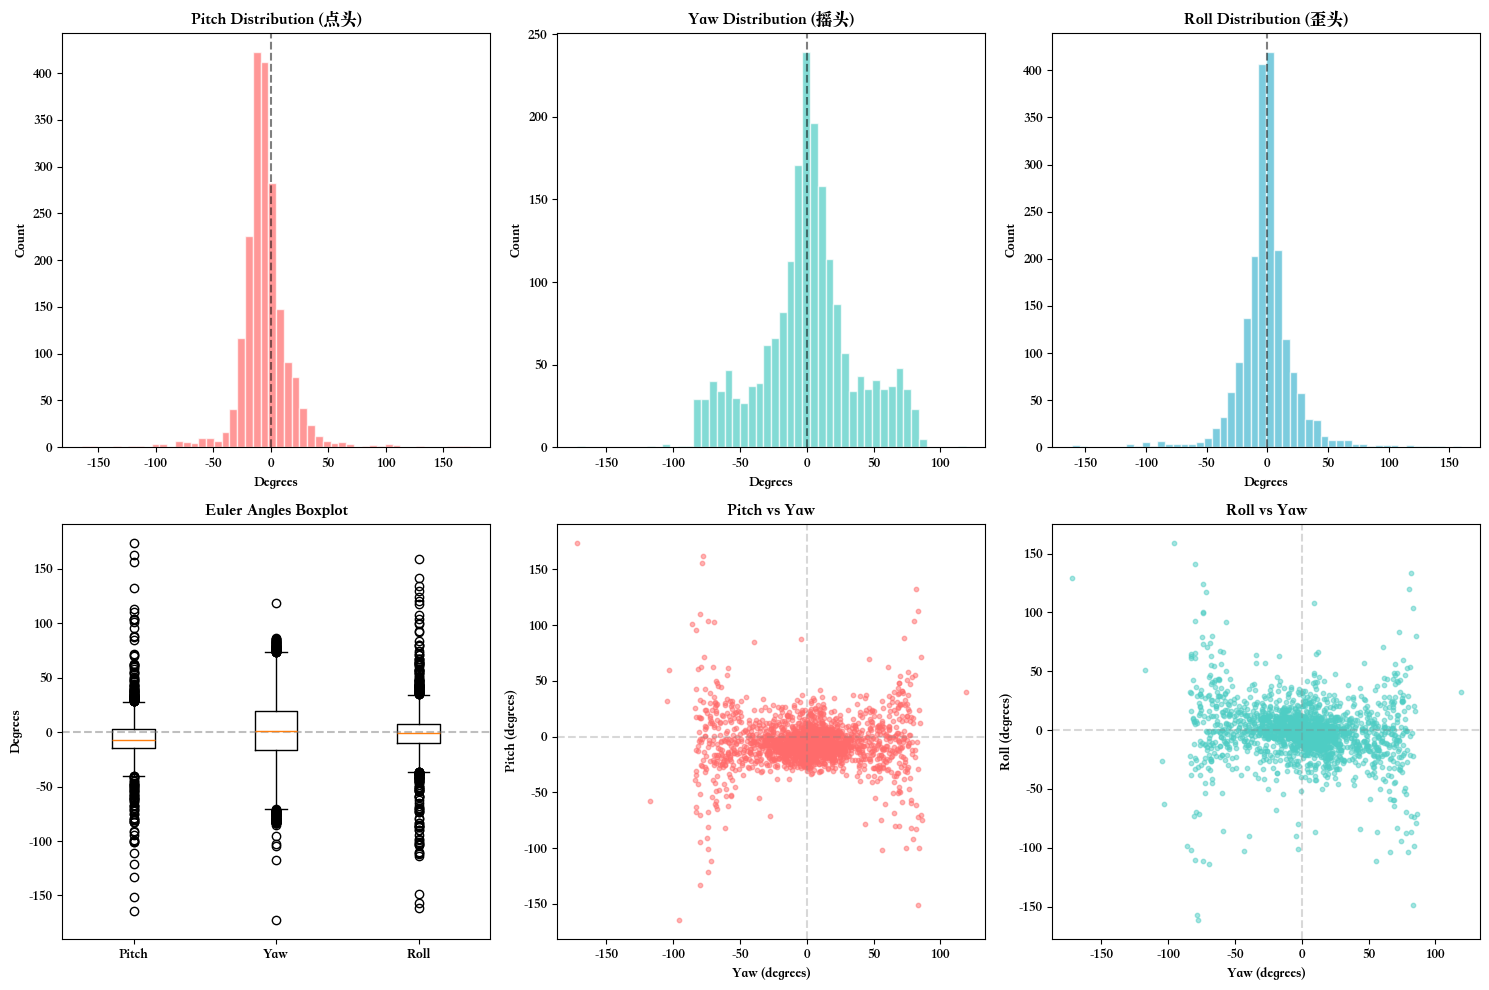


图表已保存为 aflw_euler_angles_distribution.png


In [55]:
# 可视化欧拉角分布
if len(pitches) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # 设置颜色
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
    
    # 第一行：直方图
    axes[0, 0].hist(pitches, bins=50, color=colors[0], alpha=0.7, edgecolor='white')
    axes[0, 0].set_title('Pitch Distribution (点头)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Degrees')
    axes[0, 0].set_ylabel('Count')
    axes[0, 0].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    axes[0, 1].hist(yaws, bins=50, color=colors[1], alpha=0.7, edgecolor='white')
    axes[0, 1].set_title('Yaw Distribution (摇头)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Degrees')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    axes[0, 2].hist(rolls, bins=50, color=colors[2], alpha=0.7, edgecolor='white')
    axes[0, 2].set_title('Roll Distribution (歪头)', fontsize=12, fontweight='bold')
    axes[0, 2].set_xlabel('Degrees')
    axes[0, 2].set_ylabel('Count')
    axes[0, 2].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    # 第二行：箱线图和2D散点图
    axes[1, 0].boxplot([pitches, yaws, rolls], tick_labels=['Pitch', 'Yaw', 'Roll'])
    axes[1, 0].set_title('Euler Angles Boxplot', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Degrees')
    axes[1, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    
    # Pitch vs Yaw 散点图
    axes[1, 1].scatter(yaws, pitches, alpha=0.5, s=10, c=colors[0])
    axes[1, 1].set_xlabel('Yaw (degrees)')
    axes[1, 1].set_ylabel('Pitch (degrees)')
    axes[1, 1].set_title('Pitch vs Yaw', fontsize=12, fontweight='bold')
    axes[1, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
    axes[1, 1].axvline(x=0, color='gray', linestyle='--', alpha=0.3)
    
    # Yaw vs Roll 散点图
    axes[1, 2].scatter(yaws, rolls, alpha=0.5, s=10, c=colors[1])
    axes[1, 2].set_xlabel('Yaw (degrees)')
    axes[1, 2].set_ylabel('Roll (degrees)')
    axes[1, 2].set_title('Roll vs Yaw', fontsize=12, fontweight='bold')
    axes[1, 2].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
    axes[1, 2].axvline(x=0, color='gray', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('aflw_euler_angles_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\n图表已保存为 aflw_euler_angles_distribution.png")
else:
    print("没有足够的数据进行可视化")


## 5. 样本图像可视化


In [56]:
# 检查图像尺寸分布
print("=" * 60)
print("图像尺寸分析")
print("=" * 60)

sizes = []
for jpg_file in jpg_files[:100]:  # 采样前100张
    img_path = os.path.join(DATASET_ROOT, jpg_file)
    img = cv2.imread(img_path)
    if img is not None:
        h, w = img.shape[:2]
        sizes.append((w, h))

if sizes:
    sizes_set = set(sizes)
    print(f"采样 {len(sizes)} 张图像，发现 {len(sizes_set)} 种不同尺寸:")
    
    # 统计各尺寸出现次数
    size_counts = Counter(sizes)
    for size, count in size_counts.most_common(10):
        print(f"  {size[0]}x{size[1]}: {count} 张")


图像尺寸分析
采样 100 张图像，发现 1 种不同尺寸:
  450x450: 100 张


In [57]:
# 可视化样本图像 (带关键点和姿态坐标轴)

def draw_landmarks(img, landmarks_2d, color=(0, 255, 0), radius=2):
    """
    在图像上绘制2D关键点
    """
    img_draw = img.copy()
    for pt in landmarks_2d:
        x, y = int(pt[0]), int(pt[1])
        cv2.circle(img_draw, (x, y), radius, color, -1)
    return img_draw


def draw_axis(img, pitch, yaw, roll, tdx=None, tdy=None, size=80):
    """
    在图像上绘制头部姿态的3D坐标轴
    参考: Kaggle head-pose-estimation notebook
    
    Args:
        img: BGR图像
        pitch, yaw, roll: 欧拉角 (弧度)
        tdx, tdy: 坐标轴中心点，默认为图像中心
        size: 坐标轴长度 (像素)
    
    Returns:
        绘制了坐标轴的图像
    
    坐标轴颜色:
        - 红色 (X轴): 指向右侧
        - 绿色 (Y轴): 指向下方
        - 蓝色 (Z轴): 指向前方 (从脸部射出)
    """
    from math import cos, sin
    
    img_draw = img.copy()
    
    yaw = -yaw  # Kaggle 实现中的符号约定
    
    if tdx is None or tdy is None:
        height, width = img.shape[:2]
        tdx = width / 2
        tdy = height / 2
    
    # X-Axis (红色) - 指向右侧
    x1 = size * (cos(yaw) * cos(roll)) + tdx
    y1 = size * (cos(pitch) * sin(roll) + cos(roll) * sin(pitch) * sin(yaw)) + tdy
    
    # Y-Axis (绿色) - 指向下方
    x2 = size * (-cos(yaw) * sin(roll)) + tdx
    y2 = size * (cos(pitch) * cos(roll) - sin(pitch) * sin(yaw) * sin(roll)) + tdy
    
    # Z-Axis (蓝色) - 指向前方 (从脸部射出)
    x3 = size * (sin(yaw)) + tdx
    y3 = size * (-cos(yaw) * sin(pitch)) + tdy
    
    # 绘制坐标轴
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x1), int(y1)), (0, 0, 255), 3)  # X - 红
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x2), int(y2)), (0, 255, 0), 3)  # Y - 绿
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x3), int(y3)), (255, 0, 0), 3)  # Z - 蓝
    
    # 绘制坐标轴标签
    cv2.putText(img_draw, 'X', (int(x1), int(y1)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
    cv2.putText(img_draw, 'Y', (int(x2), int(y2)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    cv2.putText(img_draw, 'Z', (int(x3), int(y3)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    
    return img_draw


def get_face_center(landmarks):
    """
    从68个关键点计算人脸中心
    使用鼻尖 (索引30) 作为中心点
    """
    if landmarks is not None and len(landmarks) > 30:
        return landmarks[30, 0], landmarks[30, 1]  # 鼻尖
    return None, None


# 随机选择9张图像
np.random.seed(42)
sample_indices = np.random.choice(len(jpg_files), min(9, len(jpg_files)), replace=False)

fig, axes = plt.subplots(3, 3, figsize=(14, 14))
axes = axes.flatten()

for idx, i in enumerate(sample_indices):
    jpg_file = jpg_files[i]
    mat_file = os.path.splitext(jpg_file)[0] + '.mat'
    
    img_path = os.path.join(DATASET_ROOT, jpg_file)
    mat_path = os.path.join(DATASET_ROOT, mat_file)
    
    img = cv2.imread(img_path)
    if img is None:
        axes[idx].text(0.5, 0.5, 'Load Error', ha='center', va='center')
        axes[idx].axis('off')
        continue
    
    # 解析标注
    landmarks, pose, roi, _ = parse_aflw_mat(mat_path)
    
    # 绘制关键点 (使用x, y坐标)
    if landmarks is not None:
        img = draw_landmarks(img, landmarks[:, :2])  # 只用前两列 (x, y)
    
    # 绘制姿态坐标轴
    if pose is not None and landmarks is not None:
        # 获取人脸中心 (鼻尖) 作为坐标轴原点
        cx, cy = get_face_center(landmarks)
        if cx is not None:
            # 转换为弧度 (draw_axis 需要弧度)
            pitch_rad = np.radians(pose[0])
            yaw_rad = np.radians(pose[1])
            roll_rad = np.radians(pose[2])
            img = draw_axis(img, pitch_rad, yaw_rad, roll_rad, tdx=cx, tdy=cy, size=80)
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img_rgb)
    
    # 显示姿态信息
    if pose is not None:
        title = f"P:{pose[0]:.1f}° Y:{pose[1]:.1f}° R:{pose[2]:.1f}°"
    else:
        title = jpg_file[:20]
    axes[idx].set_title(title, fontsize=10)
    axes[idx].axis('off')

plt.suptitle('AFLW2000 Sample Images with Landmarks & Pose Axes\n(Red=X, Green=Y, Blue=Z)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('aflw_sample_faces.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n共 {len(jpg_files)} 张图像，已随机展示 9 张样本")
print("坐标轴颜色: 红色=X(右), 绿色=Y(下), 蓝色=Z(前)")



共 2000 张图像，已随机展示 9 张样本
坐标轴颜色: 红色=X(右), 绿色=Y(下), 蓝色=Z(前)


## 6. 按姿态角度选择样本展示

展示不同角度范围的样本，验证姿态标注的正确性


In [58]:
# 收集所有数据用于按角度筛选
all_data = []

for jpg_file in jpg_files:
    mat_file = os.path.splitext(jpg_file)[0] + '.mat'
    mat_path = os.path.join(DATASET_ROOT, mat_file)
    
    if os.path.exists(mat_path):
        landmarks, pose, roi, _ = parse_aflw_mat(mat_path)
        if pose is not None:
            all_data.append({
                'jpg': jpg_file,
                'mat': mat_file,
                'pitch': pose[0],
                'yaw': pose[1],
                'roll': pose[2],
                'landmarks': landmarks
            })

print(f"成功加载 {len(all_data)} 个样本的完整数据")


成功加载 2000 个样本的完整数据


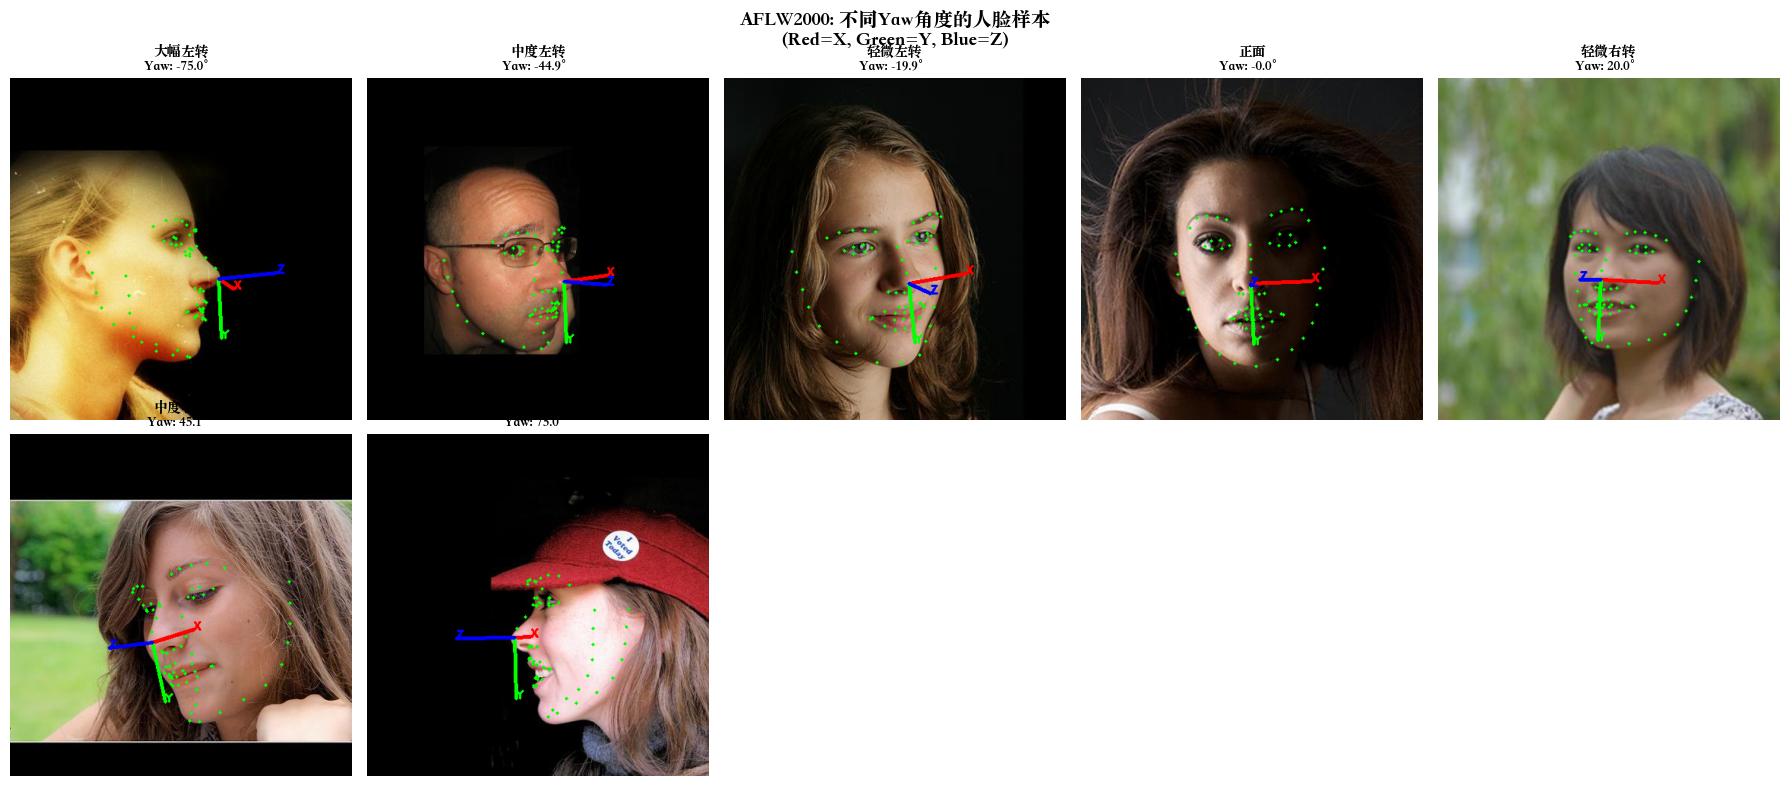

In [59]:
# 按Yaw角度展示不同朝向的人脸
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

yaw_ranges = [
    (-90, -60, '大幅左转'),
    (-60, -30, '中度左转'),
    (-30, -10, '轻微左转'),
    (-10, 10, '正面'),
    (10, 30, '轻微右转'),
    (30, 60, '中度右转'),
    (60, 90, '大幅右转'),
]

# 按yaw排序
sorted_data = sorted(all_data, key=lambda x: x['yaw'])

# 选择代表性样本
yaw_samples = []
for low, high, label in yaw_ranges:
    samples_in_range = [d for d in sorted_data if low <= d['yaw'] < high]
    if samples_in_range:
        # 选择接近中间值的样本
        mid_yaw = (low + high) / 2
        best = min(samples_in_range, key=lambda x: abs(x['yaw'] - mid_yaw))
        yaw_samples.append((best, label))

# 展示
axes_flat = axes.flatten()
for idx, (sample, label) in enumerate(yaw_samples):
    if idx >= len(axes_flat):
        break
    
    img_path = os.path.join(DATASET_ROOT, sample['jpg'])
    img = cv2.imread(img_path)
    
    if img is not None and sample['landmarks'] is not None:
        # 绘制关键点
        img = draw_landmarks(img, sample['landmarks'][:, :2])
        
        # 绘制姿态坐标轴
        cx, cy = get_face_center(sample['landmarks'])
        if cx is not None:
            pitch_rad = np.radians(sample['pitch'])
            yaw_rad = np.radians(sample['yaw'])
            roll_rad = np.radians(sample['roll'])
            img = draw_axis(img, pitch_rad, yaw_rad, roll_rad, tdx=cx, tdy=cy, size=80)
        
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes_flat[idx].imshow(img_rgb)
    
    axes_flat[idx].set_title(f"{label}\nYaw: {sample['yaw']:.1f}°", fontsize=10)
    axes_flat[idx].axis('off')

# 隐藏多余的子图
for idx in range(len(yaw_samples), len(axes_flat)):
    axes_flat[idx].axis('off')

plt.suptitle('AFLW2000: 不同Yaw角度的人脸样本\n(Red=X, Green=Y, Blue=Z)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('aflw_yaw_samples.png', dpi=150, bbox_inches='tight')
plt.show()


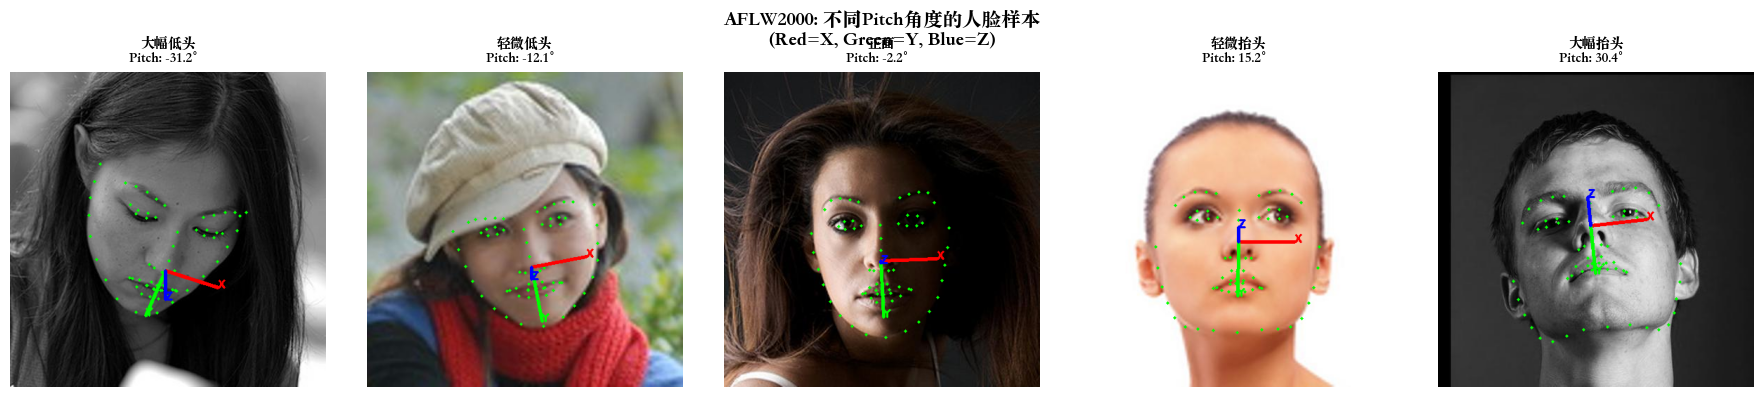

In [60]:
# 按Pitch角度展示不同俯仰的人脸
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

pitch_ranges = [
    (-90, -30, '大幅低头'),
    (-30, -10, '轻微低头'),
    (-10, 10, '正面'),
    (10, 30, '轻微抬头'),
    (30, 90, '大幅抬头'),
]

# 按pitch排序
sorted_data = sorted(all_data, key=lambda x: x['pitch'])

for idx, (low, high, label) in enumerate(pitch_ranges):
    samples_in_range = [d for d in sorted_data if low <= d['pitch'] < high]
    
    if samples_in_range:
        # 选择yaw接近0的样本（正面）
        best = min(samples_in_range, key=lambda x: abs(x['yaw']))
        
        img_path = os.path.join(DATASET_ROOT, best['jpg'])
        img = cv2.imread(img_path)
        
        if img is not None and best['landmarks'] is not None:
            # 绘制关键点
            img = draw_landmarks(img, best['landmarks'][:, :2])
            
            # 绘制姿态坐标轴
            cx, cy = get_face_center(best['landmarks'])
            if cx is not None:
                pitch_rad = np.radians(best['pitch'])
                yaw_rad = np.radians(best['yaw'])
                roll_rad = np.radians(best['roll'])
                img = draw_axis(img, pitch_rad, yaw_rad, roll_rad, tdx=cx, tdy=cy, size=80)
            
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img_rgb)
        
        axes[idx].set_title(f"{label}\nPitch: {best['pitch']:.1f}°", fontsize=10)
    
    axes[idx].axis('off')

plt.suptitle('AFLW2000: 不同Pitch角度的人脸样本\n(Red=X, Green=Y, Blue=Z)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('aflw_pitch_samples.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. 3D关键点分析


3D关键点分析

关键点数量分布:
  最小: 68
  最大: 68
  众数: 68


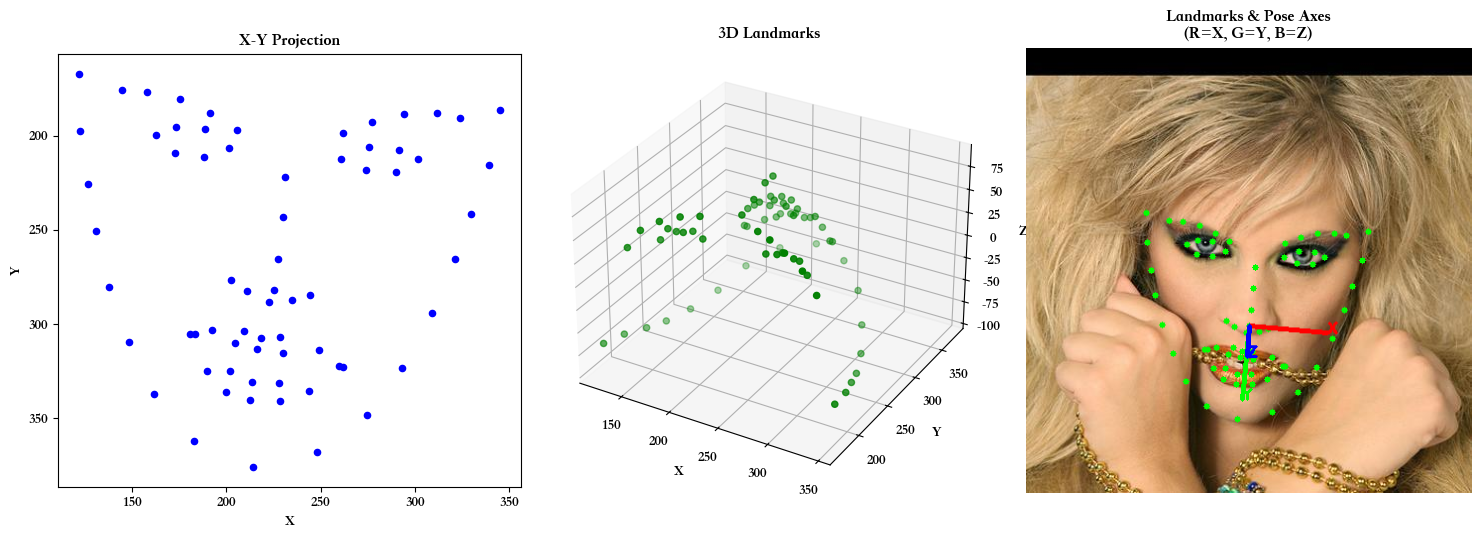

In [61]:
# 分析3D关键点的分布
if landmarks_list:
    print("=" * 60)
    print("3D关键点分析")
    print("=" * 60)
    
    # 统计关键点数量
    num_landmarks = [lm.shape[0] for lm in landmarks_list if lm is not None]
    print(f"\n关键点数量分布:")
    print(f"  最小: {min(num_landmarks)}")
    print(f"  最大: {max(num_landmarks)}")
    print(f"  众数: {max(set(num_landmarks), key=num_landmarks.count)}")
    
    # 选择一个样本可视化3D关键点
    sample_landmarks = landmarks_list[0]
    
    fig = plt.figure(figsize=(15, 5))
    
    # 2D投影 (X-Y)
    ax1 = fig.add_subplot(131)
    ax1.scatter(sample_landmarks[:, 0], sample_landmarks[:, 1], c='blue', s=20)
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_title('X-Y Projection')
    ax1.invert_yaxis()  # 图像坐标系Y轴向下
    ax1.set_aspect('equal')
    
    # 3D视图
    ax2 = fig.add_subplot(132, projection='3d')
    ax2.scatter(sample_landmarks[:, 0], sample_landmarks[:, 1], sample_landmarks[:, 2], c='green', s=20)
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_zlabel('Z')
    ax2.set_title('3D Landmarks')
    
    # 对应的图像 (带关键点和姿态坐标轴)
    ax3 = fig.add_subplot(133)
    sample_jpg = jpg_files[0]
    sample_mat = os.path.splitext(sample_jpg)[0] + '.mat'
    img = cv2.imread(os.path.join(DATASET_ROOT, sample_jpg))
    if img is not None:
        # 绘制关键点
        img = draw_landmarks(img, sample_landmarks[:, :2], radius=3)
        
        # 绘制姿态坐标轴
        _, pose, _, _ = parse_aflw_mat(os.path.join(DATASET_ROOT, sample_mat))
        if pose is not None:
            cx, cy = get_face_center(sample_landmarks)
            if cx is not None:
                pitch_rad = np.radians(pose[0])
                yaw_rad = np.radians(pose[1])
                roll_rad = np.radians(pose[2])
                img = draw_axis(img, pitch_rad, yaw_rad, roll_rad, tdx=cx, tdy=cy, size=80)
        
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax3.imshow(img_rgb)
    ax3.set_title('Landmarks & Pose Axes\n(R=X, G=Y, B=Z)')
    ax3.axis('off')
    
    plt.tight_layout()
    plt.savefig('aflw_3d_landmarks.png', dpi=150, bbox_inches='tight')
    plt.show()


## 8. 数据质量检查与总结


In [62]:
# 数据完整性检查
print("=" * 60)
print("AFLW2000-3D Dataset Summary Report")
print("=" * 60)

print(f"\n📁 数据集路径: {DATASET_ROOT}")
print(f"\n📊 文件统计:")
print(f"  图像文件 (.jpg): {len(jpg_files)}")
print(f"  标注文件 (.mat): {len(mat_files)}")
print(f"  完整配对: {len(matched)}")

print(f"\n✅ 成功解析: {len(pitches)} 个样本")
if len(failed) > 0:
    print(f"❌ 解析失败: {len(failed)} 个样本")

# 数据质量评估
print("\n" + "-" * 60)
print("数据质量评估:")
print("-" * 60)

if len(pitches) > 0:
    # 过滤统计
    mask_90 = (np.abs(pitches) <= 90) & (np.abs(yaws) <= 90) & (np.abs(rolls) <= 90)
    mask_99 = (np.abs(pitches) <= 99) & (np.abs(yaws) <= 99) & (np.abs(rolls) <= 99)
    
    print(f"\n角度范围统计:")
    print(f"  全部样本: {len(pitches)}")
    print(f"  |angle| ≤ 90°: {mask_90.sum()} ({100*mask_90.sum()/len(pitches):.1f}%)")
    print(f"  |angle| ≤ 99°: {mask_99.sum()} ({100*mask_99.sum()/len(pitches):.1f}%)")
    
    # 过滤后的角度范围
    print(f"\n过滤后角度范围 (|angle| ≤ 90°):")
    print(f"  Pitch: [{pitches[mask_90].min():.1f}°, {pitches[mask_90].max():.1f}°]")
    print(f"  Yaw:   [{yaws[mask_90].min():.1f}°, {yaws[mask_90].max():.1f}°]")
    print(f"  Roll:  [{rolls[mask_90].min():.1f}°, {rolls[mask_90].max():.1f}°]")
    
    print(f"\n⚠️ 注意: 约 {len(pitches) - mask_90.sum()} 个样本有极端角度 (|angle| > 90°)")
    print("   这些样本可能存在标注问题，建议在训练/评估时过滤")

# 与BIWI对比
print("\n" + "-" * 60)
print("与 BIWI 数据集对比:")
print("-" * 60)
print("| 特性 | AFLW2000 | BIWI |")
print("|------|----------|------|")
print(f"| 样本数 | {len(pitches)} | 15,677 |")
print("| 场景 | 真实野外 | 实验室 |")
print("| 传感器 | 普通相机 | Kinect |")
print("| 关键点 | 68个 3D | 无 |")
print("| 特点 | 大角度姿态 | 连续视频帧 |")

print("\n" + "=" * 60)
print("EDA 完成!")
print("=" * 60)


AFLW2000-3D Dataset Summary Report

📁 数据集路径: /Users/eddiesyn/temp/public_dataset/AFLW2000

📊 文件统计:
  图像文件 (.jpg): 2000
  标注文件 (.mat): 2000
  完整配对: 2000

✅ 成功解析: 2000 个样本

------------------------------------------------------------
数据质量评估:
------------------------------------------------------------

角度范围统计:
  全部样本: 2000
  |angle| ≤ 90°: 1964 (98.2%)
  |angle| ≤ 99°: 1969 (98.5%)

过滤后角度范围 (|angle| ≤ 90°):
  Pitch: [-83.0°, 88.3°]
  Yaw:   [-83.7°, 86.6°]
  Roll:  [-87.1°, 83.7°]

⚠️ 注意: 约 36 个样本有极端角度 (|angle| > 90°)
   这些样本可能存在标注问题，建议在训练/评估时过滤

------------------------------------------------------------
与 BIWI 数据集对比:
------------------------------------------------------------
| 特性 | AFLW2000 | BIWI |
|------|----------|------|
| 样本数 | 2000 | 15,677 |
| 场景 | 真实野外 | 实验室 |
| 传感器 | 普通相机 | Kinect |
| 关键点 | 68个 3D | 无 |
| 特点 | 大角度姿态 | 连续视频帧 |

EDA 完成!
